# 16 — Sea-level-rise risk: SaTScan clusters → GeoAI story map

![User-supplied Six Thinking Hats illustration for global-health discussion](assets/six-thinking-hats-global-health.png)

This lab turns the SaTScan cluster summary embedded in `Prototype-July-8-2024.pbix` into a browser-first GeoAI investigation. The report’s `ALLMODELS` table supplies cluster rank, flood facilities, observed/expected ratio, relative risk, radius, and significance. Its `Climate-Sites-w-coords` table supplies city coordinates, elevation context, and scenario flood indicators.

This is a decision-support teaching example—not a new SaTScan run, a forecast, or a validated flood-hazard map.

## Start here: the question behind the code

**How can we explore the report's top ten clusters without mixing metrics?**

**What you will learn:** read → compare → animate → interpret. The numbered reading guides below follow the actual code cells. Read a guide, predict the output, then run its cell with **Shift+Enter**. Run from top to bottom; changing an upstream value requires rerunning the cells that use it.

**GeoAI connection:** Evidence interpretation supporting GeoAI: this notebook visualizes existing SaTScan results and fits no new model.

**Why this is useful:** Linked views help compare statistical risk, reported facilities and scenario indicators while exposing what additional evidence a decision needs.

**Where the work happens:** The small bundled PBIX derivative is read locally; Plotly shows bars, scenario bubbles and 3D points. GeoLibre maps representative city coordinates.

![Keep the risk axes honest. Start with ten cluster-ranked report rows and documented city aggregates. Display relative risk separately from original rank and facility counts. Compare A/B/C indicators as alternative scenarios, not as a forecast movie. Read 3D height as relative risk; it is not terrain or floodwater depth.](assets/learning/16/infographic.svg)

### Watch the idea unfold

[![Preview: Keep the risk axes honest — 32-second captioned walkthrough](assets/learning/16/poster.png)](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/16/watch.html)

[▶ Watch the captioned mini-video and read its transcript](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/16/watch.html) · [Launch this notebook](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/lab/index.html?path=16_sea_level_rise_sat_scan_geoai.ipynb) · [Read this Book chapter](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/notebooks/16_sea_level_rise_sat_scan_geoai.html) · [Python and browser learning guide](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/learning-guide.html)

The video is a silent four-step teaching storyboard with player controls and captions. Open the companion page to play, pause, seek or download it. The local copy is bundled under `assets/learning/16/`; downloaded media can be played offline. The infographic and the text below cover the same ideas without a video player.

**Video transcript:**

1. **Read (0–8 s):** Start with ten cluster-ranked report rows and documented city aggregates. Code landmark: `pd.read_csv(...)`.

2. **Compare (8–16 s):** Display relative risk separately from original rank and facility counts. Code landmark: `sort_values('relative_risk')`.

3. **Animate (16–24 s):** Compare A/B/C indicators as alternative scenarios, not as a forecast movie. Code landmark: `risk.melt(...)`.

4. **Interpret (24–32 s):** Read 3D height as relative risk; it is not terrain or floodwater depth. Code landmark: `z=risk.relative_risk`.


### Code guide 1 — Read the small report derivative

**Read the Python:** The browser setup installs the plotting and map tools. `read_csv` loads the bundled ten-row summary. Adding city and country strings creates a readable label without changing the original rank or risk fields.

**Look for:** Ten reported cluster summaries from the supplied PBIX, with supporting city-level aggregates.

**Pause and try:** Compare `all_facilities` and `n_sites`: these come from different table summaries and must not be treated as the same denominator.


In [1]:
import sys
if sys.platform == 'emscripten':
    import pyodide_js
    await pyodide_js.loadPackage(['numpy', 'pandas', 'matplotlib'])
    import micropip
    await micropip.install(['geolibre==3.0.0', 'pyodide-http', 'plotly==6.5.0'])
    import pyodide_http
    pyodide_http.patch_all()
from geolibre_lite import LiteMap as Map
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from cognition import plotly_view, style_plots
style_plots()
risk = pd.read_csv('data/pbix_top10_sat_scan.csv')
risk['city_label'] = risk['city_name'] + ', ' + risk['country']
assert len(risk) == 10 and risk['city_name'].notna().all()
risk


,cluster_rank,country,city_name,flood_facilities,all_facilities,llr,radius_km,observed_vs_expected,p_value,relative_risk,n_sites,latitude,longitude,mhhw_median_m,effective_elevation_median,flood_a_mean,flood_b_mean,flood_c_mean,flood_all_mean,city_label
0,1,Cote d'Ivoire,Abidjan,110,259,197.889989,12.907814,14.918462,1.000000e-17,15.898635,490,5.311875,-3.996441,6.150,6.15,0.271429,0.273469,0.285714,0.285714,"Abidjan, Cote d'Ivoire"
1,2,Thailand,Bangkok,75,84,187.414979,19.676778,31.362675,1.000000e-17,32.788599,91,13.756460,100.536666,2.010,2.10,0.879121,0.879121,0.901099,0.901099,"Bangkok, Thailand"
2,3,Vietnam,Ho Chi Minh City,76,109,171.792135,16.130105,24.491660,1.000000e-17,25.610310,152,10.783389,106.669728,3.040,3.20,0.447368,0.453947,0.546053,0.546053,"Ho Chi Minh City, Vietnam"
3,4,India,Bombay,70,84,170.142893,7.547710,29.271830,1.000000e-17,30.507179,139,19.076000,72.877660,2.850,2.85,0.071942,0.086331,0.546763,0.546763,"Bombay, India"
4,5,Nigeria,Lagos,69,176,118.211997,19.326452,13.771066,1.000000e-17,14.320787,326,6.536185,3.333835,7.930,7.93,0.153374,0.156442,0.242331,0.242331,"Lagos, Nigeria"
5,6,Nigeria,Warri,53,89,111.456243,19.373746,20.917847,1.000000e-17,21.569883,295,5.507600,5.919480,4.030,4.16,0.332203,0.342373,0.366102,0.366102,"Warri, Nigeria"
6,7,Cameroon,Douala,77,274,108.560602,15.195732,9.871230,1.000000e-17,10.299497,391,4.059251,9.727429,13.250,13.25,0.171355,0.179028,0.202046,0.202046,"Douala, Cameroon"
7,8,Tanzania,Zanzibar,31,54,63.921139,6.113379,20.165039,1.000000e-17,20.527084,224,-6.161805,39.218115,16.910,16.91,0.223214,0.236607,0.245536,0.245536,"Zanzibar, Tanzania"
8,9,Nigeria,Bugama,27,37,61.840233,19.915587,25.632630,1.000000e-17,26.036934,132,4.854035,6.431200,2.365,2.59,0.507576,0.507576,0.522727,0.522727,"Bugama, Nigeria"
9,10,Trinidad & Tobago,Port-of-Spain,22,22,57.060402,19.736025,35.126197,1.000000e-17,35.581212,61,10.649853,-61.423960,18.930,18.93,0.016393,0.032787,0.049180,0.049180,"Port-of-Spain, Trinidad & Tobago"


## Evidence story 1 — What does the PBIX evidence say?

SaTScan identifies unusually concentrated spatial risk. Rank and relative risk are evidence about reported clusters; they are not interchangeable with meters of water, population exposed, or a probability that a particular building floods.

The following views are independent: selecting a point does not filter the other charts. The saved figure and table work in the Book; run the notebook for the GeoLibre map. This is a narrative notebook, not an exported GeoLibre story-map project.


### Code guide 2 — Compare rank, relative risk and location

**Read the Python:** Sorting the bar chart by relative risk changes display order, not the report's cluster rank. `itertuples` makes one representative city point per row, with properties for inspection. These points are not cluster boundaries.

**Look for:** Relative-risk bars colored by facility count and a 2D map of the ten reported clusters' representative city locations.

**Pause and try:** Identify the highest relative-risk bar. Is it also cluster rank 1 in the original report?


C:\Users\duf2\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\display.py:447: UserWarning:

Consider using IPython.display.IFrame instead



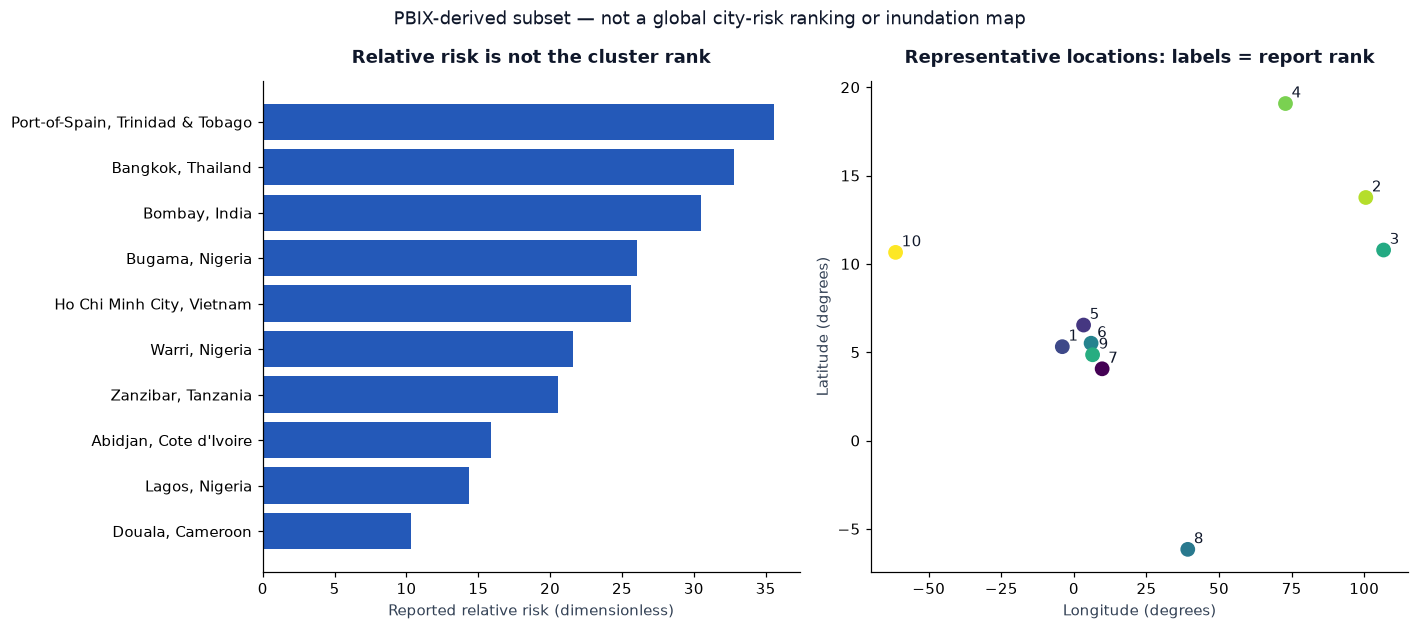

,cluster_rank,city_label,relative_risk,flood_facilities,longitude,latitude
0,1,"Abidjan, Cote d'Ivoire",15.898635,110,-3.996441,5.311875
1,2,"Bangkok, Thailand",32.788599,75,100.536666,13.756460
2,3,"Ho Chi Minh City, Vietnam",25.610310,76,106.669728,10.783389
3,4,"Bombay, India",30.507179,70,72.877660,19.076000
4,5,"Lagos, Nigeria",14.320787,69,3.333835,6.536185
5,6,"Warri, Nigeria",21.569883,53,5.919480,5.507600
6,7,"Douala, Cameroon",10.299497,77,9.727429,4.059251
7,8,"Zanzibar, Tanzania",20.527084,31,39.218115,-6.161805
8,9,"Bugama, Nigeria",26.036934,27,6.431200,4.854035
9,10,"Port-of-Spain, Trinidad & Tobago",35.581212,22,-61.423960,10.649853


In [2]:
fig = px.bar(risk.sort_values('relative_risk'), x='relative_risk', y='city_label', orientation='h', color='flood_facilities', color_continuous_scale='Turbo', labels={'relative_risk':'SaTScan relative risk (report units)','city_label':'City','flood_facilities':'Flood facilities'})
fig.update_layout(height=560, title='Reported SaTScan clusters: relative risk and flood-facility count')
display(plotly_view(fig, height=580, title='Reported relative risk by city'))

# Saved alternatives do not need JavaScript, basemaps or a running kernel.
ordered = risk.sort_values('relative_risk')
preview, axes = plt.subplots(1, 2, figsize=(13, 5.8))
axes[0].barh(ordered.city_label, ordered.relative_risk, color='#2459b8')
axes[0].set(xlabel='Reported relative risk (dimensionless)', title='Relative risk is not the cluster rank')
axes[1].scatter(risk.longitude, risk.latitude, c=risk.relative_risk, cmap='viridis', s=75)
for row in risk.itertuples():
    axes[1].annotate(str(row.cluster_rank), (row.longitude, row.latitude), xytext=(4, 4), textcoords='offset points')
axes[1].set(xlabel='Longitude (degrees)', ylabel='Latitude (degrees)', title='Representative locations: labels = report rank')
preview.suptitle('PBIX-derived subset — not a global city-risk ranking or inundation map')
plt.tight_layout()
plt.show()
display(risk[['cluster_rank', 'city_label', 'relative_risk', 'flood_facilities', 'longitude', 'latitude']])
m = Map(center=(35, 35), zoom=1.3, height='650px')
features = [{'type':'Feature','geometry':{'type':'Point','coordinates':[r.longitude,r.latitude]},'properties':{'city':r.city_label,'cluster_rank':int(r.cluster_rank),'relative_risk':float(r.relative_risk),'flood_facilities':int(r.flood_facilities)}} for r in risk.itertuples()]
m.add_geojson({'type':'FeatureCollection','features':features}, name='PBIX SaTScan top 10', circleRadius=8, fillColor='#e45756', fillOpacity=0.8, strokeColor='#351c75', strokeWidth=1.5)
m


## Evidence story 2 — Scenario animation

The PBIX includes three scenario columns summarized here as A, B, and C. The animation is a sense-making device: it asks where the pattern changes most without pretending that a scenario value is direct water depth.

**Play or select A/B/C below.** City identities, axis order, symbol scaling and color limits are shared across frames. A/B/C are report field labels, not verified sea-level increments or dates; their definitions and extraction provenance still need confirmation. The adjacent table and static panels expose all values without relying on motion.


### Code guide 3 — Reshape columns for a scenario animation

**Read the Python:** `melt` turns the A/B/C columns into thirty rows: one city-scenario combination per row. A dictionary maps field names to scenario labels. `animation_frame` changes the displayed scenario while size and color encode the indicator.

**Look for:** A scenario-comparison animation. A/B/C labels represent alternatives, not a measured time sequence or rising water surface.

**Pause and try:** Check a changing bubble against the table. Why cannot its indicator value be read as metres of floodwater?


C:\Users\duf2\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\display.py:447: UserWarning:

Consider using IPython.display.IFrame instead



,A,B,C
city_label,,,
"Abidjan, Cote d'Ivoire",0.271429,0.273469,0.285714
"Bangkok, Thailand",0.879121,0.879121,0.901099
"Ho Chi Minh City, Vietnam",0.447368,0.453947,0.546053
"Bombay, India",0.071942,0.086331,0.546763
"Lagos, Nigeria",0.153374,0.156442,0.242331
"Warri, Nigeria",0.332203,0.342373,0.366102
"Douala, Cameroon",0.171355,0.179028,0.202046
"Zanzibar, Tanzania",0.223214,0.236607,0.245536
"Bugama, Nigeria",0.507576,0.507576,0.522727


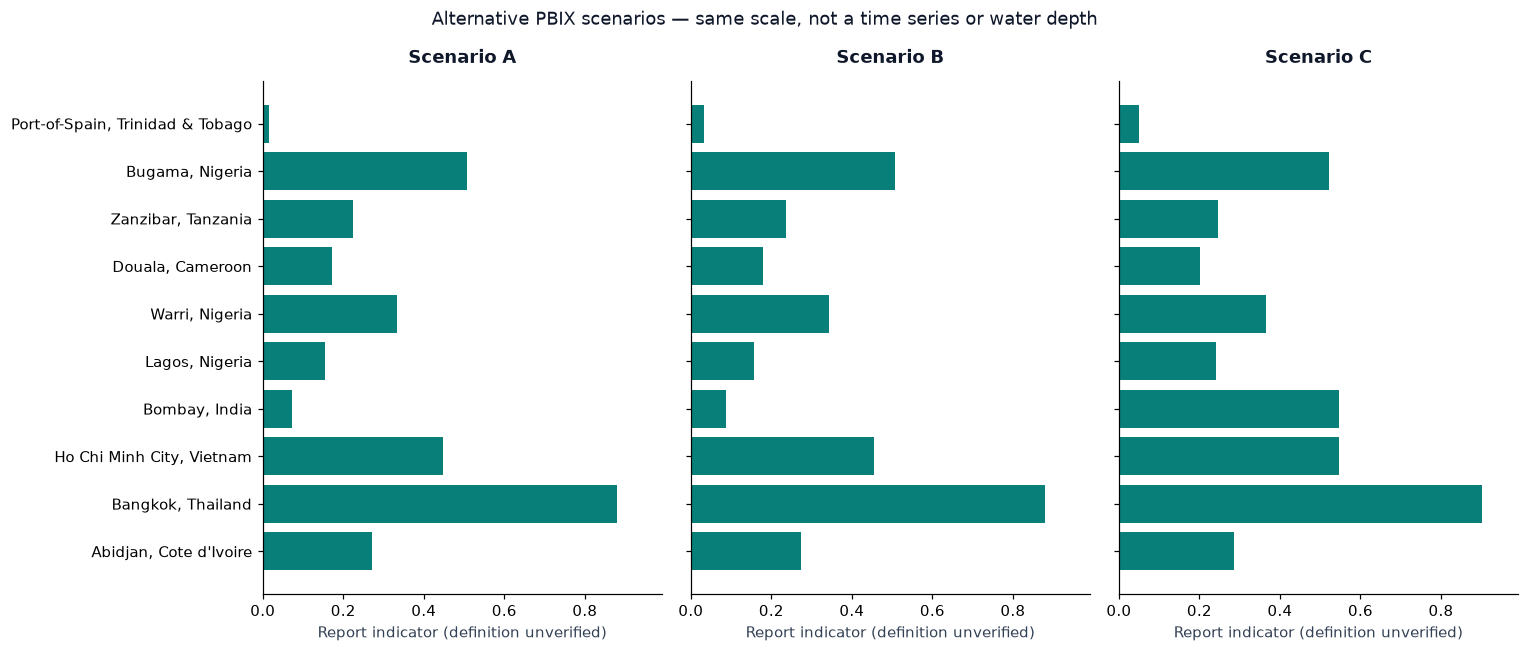

In [3]:
scenario_cols = {'A':'flood_a_mean','B':'flood_b_mean','C':'flood_c_mean'}
long = risk.melt(id_vars=['city_label','relative_risk'], value_vars=list(scenario_cols.values()), var_name='scenario', value_name='scenario_indicator')
long['scenario'] = long['scenario'].map({v:k for k,v in scenario_cols.items()})
fig = px.scatter(long, x='relative_risk', y='city_label', animation_frame='scenario', animation_group='city_label',
                 category_orders={'scenario': ['A', 'B', 'C'], 'city_label': risk.city_label.tolist()},
                 range_x=[0, float(risk.relative_risk.max()) * 1.1],
                 range_color=[0, float(long.scenario_indicator.max())], size_max=35, size='scenario_indicator', color='scenario_indicator', color_continuous_scale='Viridis', hover_name='city_label', labels={'relative_risk':'SaTScan relative risk','city_label':'City','scenario_indicator':'PBIX scenario indicator'})
fig.update_layout(height=620, title='Animated scenario comparison — PBIX flood indicator, not water depth')
display(plotly_view(fig, height=650, title='Play or select report scenarios A, B and C; these are not dates'))

# A table and simultaneous panels make every frame inspectable without animation.
scenario_table = risk.set_index('city_label')[list(scenario_cols.values())].rename(columns={v:k for k,v in scenario_cols.items()})
display(scenario_table)
preview, axes = plt.subplots(1, 3, figsize=(14, 6), sharex=True, sharey=True)
for ax, label in zip(axes, ['A', 'B', 'C']):
    ax.barh(scenario_table.index, scenario_table[label], color='#087f78')
    ax.set(title=f'Scenario {label}', xlabel='Report indicator (definition unverified)', xlim=(0, float(long.scenario_indicator.max()) * 1.1))
preview.suptitle('Alternative PBIX scenarios — same scale, not a time series or water depth')
plt.tight_layout()
plt.show()


## Evidence story 3 — 3D risk and a responsible GeoAI deep dive

A 3D view can show several dimensions at once, but it can also create false confidence. Height encodes relative risk, point size encodes facilities, and color encodes the all-scenario indicator. Always compare it with the table and 2D map.

The interactive point size is clipped for legibility, so it is not a proportional count scale. Hover and use the source table for exact values. The static counterpart uses equal marker sizes. These are statistical scenes, not 3D buildings or inundation surfaces.


### Code guide 4 — Read the three-dimensional axes literally

**Read the Python:** Longitude, latitude and relative risk become x, y and z. `np.clip` bounds marker sizes for legibility, so size is only a display cue. Color uses the all-scenario mean from the supporting sites table.

**Look for:** A rotatable 3D statistical scatter; the vertical axis is relative risk, not terrain elevation or water depth.

**Pause and try:** Compare the 3D view with the bars before drawing a conclusion; the camera can obscure points.


C:\Users\duf2\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\display.py:447: UserWarning:

Consider using IPython.display.IFrame instead



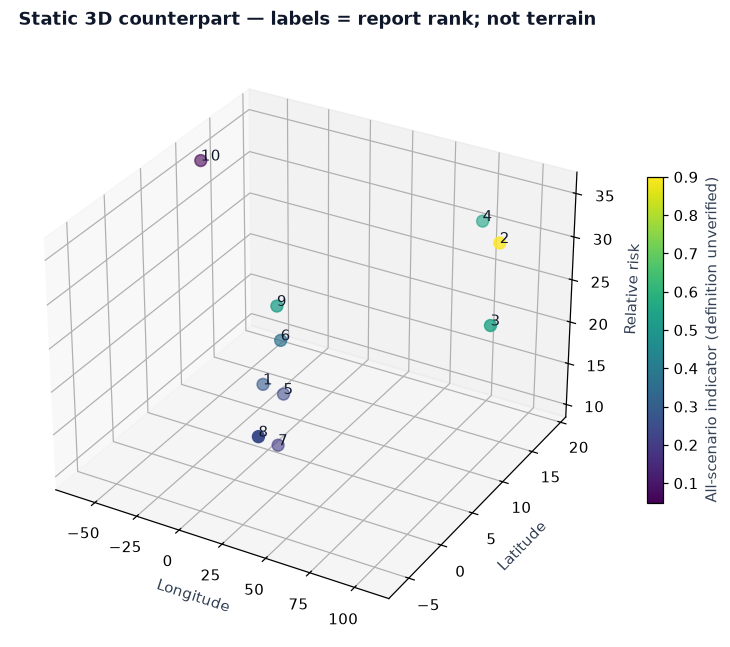

In [4]:
fig3d = go.Figure(go.Scatter3d(x=risk.longitude, y=risk.latitude, z=risk.relative_risk, mode='markers+text', text=risk.city_name, textposition='top center', marker={'size':np.clip(risk.flood_facilities/18,6,18),'color':risk.flood_all_mean,'colorscale':'Viridis','showscale':True,'colorbar':{'title':'All-scenario indicator'}}, hovertemplate='%{text}<br>relative risk=%{z:.1f}<extra></extra>'))
fig3d.update_layout(height=680, title='3D sense-making view: location × relative risk × reported facilities', scene={'xaxis_title':'Longitude','yaxis_title':'Latitude','zaxis_title':'Relative risk'})
display(plotly_view(fig3d, height=700, title='Rotate the report location and relative-risk view; vertical height is not water depth'))

preview = plt.figure(figsize=(10, 7))
ax = preview.add_subplot(111, projection='3d')
points = ax.scatter(risk.longitude, risk.latitude, risk.relative_risk, c=risk.flood_all_mean, cmap='viridis', s=60)
for row in risk.itertuples():
    ax.text(row.longitude, row.latitude, row.relative_risk, str(row.cluster_rank))
ax.set(xlabel='Longitude', ylabel='Latitude', zlabel='Relative risk', title='Static 3D counterpart — labels = report rank; not terrain')
preview.colorbar(points, ax=ax, shrink=0.55, label='All-scenario indicator (definition unverified)')
plt.show()


## Six perspectives for the next decision

- **White / evidence:** Which source field, date, denominator, and spatial unit support each claim?
- **Red / experience:** What would residents, responders, and health workers notice that the table cannot show?
- **Black / caution:** Where could missing data, geocoding, model assumptions, or map design harm a community?
- **Yellow / opportunity:** Which early-warning, planning, or service-access decision could this evidence improve?
- **Green / alternatives:** What other data, methods, or community-led interpretations should challenge the first model?
- **Blue / process:** Who owns the next action, what gets validated, and when do we stop using the model?
- **Purple / synthesis:** What is the smallest accountable next step that preserves disagreement and makes uncertainty visible?

A useful GeoAI workflow is **discover → join → engineer → compare → explain → challenge**. The PBIX SaTScan result identifies reported spatial clusters; the scenario fields provide a comparative teaching layer. The next responsible step is validation with local data and accountable partners—not a stronger claim.

## Data & software citations

- User-supplied Power BI report: `Prototype-July-8-2024.pbix`. The committed CSV is a derived top-10 summary, not the complete report model.
- SaTScan-derived report table: `ALLMODELS`; supporting table: `Climate-Sites-w-coords`.
- [GeoLibre](https://geolibre.app/), [GeoAI](https://opengeoai.org/), and [Plotly Python](https://plotly.com/python/).
- Six Thinking Hats concepts are associated with Edward de Bono; the purple synthesis framing and supplied graphic are retained as teaching context.
- Preserve the report’s original source citations and licensing before publishing any derivative result.

## Make sense of the result

![A taller point means deeper flooding? Here the z axis is a statistical relative risk. I will read the axes and check the source denominators.](assets/learning/16/cartoon.svg)

**Cartoon transcript:** A taller point means deeper flooding? → Here the z axis is a statistical relative risk. → I will read the axes and check the source denominators.

**Explain it to a colleague:** Why should the two facility/site counts not be interchanged?

<details><summary>Check your reasoning</summary>

ALLMODELS cluster counts and supporting city-site aggregates use different selections; their denominators need separate interpretation.

</details>

Write three sentences: **I used…** (source and units), **the code computed…** (method), and **I can conclude…** (plus a remaining question). Point to the map, chart or table that supports each claim.

All new teaching illustrations are original schematics. Their marks and fictional dialogue are explanatory, not observations, fitted predictions or captured AI conversations. The existing citation cells identify the analytical data.


## GeoLibre creator and software attribution

GeoLibre is developed by **Qiusheng Wu and contributors**. Recommended citation: Wu, Q. (2026). *GeoLibre: A lightweight, cloud-native GIS platform for visualizing, exploring, and analyzing geospatial data.* Zenodo. [doi:10.5281/zenodo.20785400](https://doi.org/10.5281/zenodo.20785400). See [the official citation guidance](https://geolibre.app/citation/) and [source and MIT license](https://github.com/opengeos/GeoLibre). These browser lessons pin the Python builders to `geolibre==3.0.0`; the independently hosted viewer may change. This repository supplies the JupyterLite adapter and teaching materials, not the upstream GIS. Keep the original dataset, demo-author and basemap credits when sharing a result.
